# Q15: population spiking complexity

This notebook is intentionally limited to reviewing and plotting saved Q15 results. Run `q15_complexity.py` to compute rate-normalized population Lempel–Ziv complexity, then run `q15_complexity_stats.R` for mouse-level inference. The computational script checkpoints its subsample CSV after every bin width.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

In [2]:
repository_folder = Path(os.environ.get(
    "CON2PHYS_REPOSITORY_DIR", "D:/git_repos/con2phys_submission"
))
q_path = repository_folder / "results" / "q15"
mouse_area_path = q_path / "q15_lzc_mouse_area_bin.csv"
area_summary_path = q_path / "q15_lzc_area_summary.csv"
run_config_path = q_path / "q15_run_config.json"
stats_means_path = q_path / "q15_complexity_stats_means.csv"
answer_path = q_path / "answer.txt"

required_paths = [mouse_area_path, area_summary_path, run_config_path]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Run code/questions/q15_complexity.py first. Missing: "
        + ", ".join(map(str, missing_paths))
    )

## Descriptive mouse-level results

In [3]:
mouse_area_df = pd.read_csv(mouse_area_path)
area_summary_df = pd.read_csv(area_summary_path)
expected_widths = {10, 20, 50}
if len(mouse_area_df) != 18 * 3 * 3:
    raise ValueError("Expected 162 mouse-area-bin rows")
if set(mouse_area_df["bin_width_ms"]) != expected_widths:
    raise ValueError("Expected 10, 20, and 50 ms bin widths")
display(area_summary_df)
display(mouse_area_df.head())

,brain_area,bin_width_ms,mean_normalized_lz_complexity,sd_normalized_lz_complexity,mean_observed_compression_ratio,mean_spike_bin_density,n_mice,sem_normalized_lz_complexity,ci95_low,ci95_high
0,1,10,0.971974,0.017244,0.477546,0.073789,18,0.004064,0.964008,0.979940
1,1,20,0.976468,0.015770,0.625939,0.134017,18,0.003717,0.969183,0.983753
2,1,50,0.982219,0.014079,0.815212,0.263610,18,0.003319,0.975714,0.988723
3,2,10,0.945686,0.053527,0.383019,0.050985,18,0.012617,0.920957,0.970414
4,2,20,0.943312,0.054109,0.509939,0.095911,18,0.012754,0.918315,0.968309
5,2,50,0.935773,0.053000,0.672939,0.200374,18,0.012492,0.911288,0.960258
6,3,10,0.944538,0.035433,0.443841,0.067110,18,0.008352,0.928169,0.960907
7,3,20,0.950140,0.029546,0.576997,0.120563,18,0.006964,0.936491,0.963790
8,3,50,0.956123,0.027089,0.741638,0.229856,18,0.006385,0.943609,0.968638


,mouse_id,brain_area,bin_width_ms,mean_normalized_lz_complexity,sd_normalized_lz_complexity,mean_observed_compression_ratio,mean_surrogate_compressed_bytes,mean_spike_bin_density,n_trials,n_time_bins,total_analyzed_time_sec,n_available_units,n_sampled_units,n_subsamples,n_rate_surrogates
0,1,1,10,0.976875,0.017149,0.486628,40410.35,0.077980,407,92641,926.41,59,7,20,1
1,1,1,20,0.981068,0.013709,0.637758,26287.90,0.139347,407,46224,924.48,59,7,20,1
2,1,1,50,0.987532,0.013598,0.832019,13526.35,0.273385,407,18353,917.65,59,7,20,1
3,1,2,10,0.946674,0.033255,0.416715,35596.35,0.063211,407,92641,926.41,22,7,20,1
4,1,2,20,0.942339,0.027618,0.536958,23020.05,0.112283,407,46224,924.48,22,7,20,1


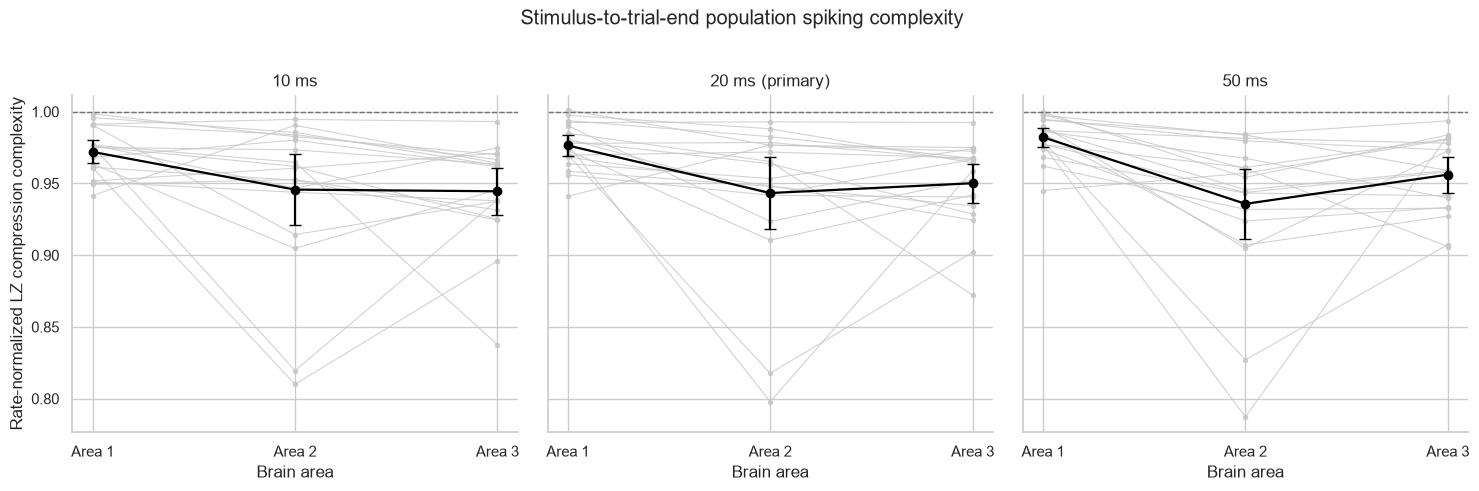

In [4]:
sns.set_theme(style="whitegrid")
bin_widths = sorted(mouse_area_df["bin_width_ms"].unique())
fig, axes = plt.subplots(1, len(bin_widths), figsize=(5 * len(bin_widths), 4.8), sharey=True)
for ax, bin_width_ms in zip(np.atleast_1d(axes), bin_widths):
    plot_df = mouse_area_df.loc[mouse_area_df["bin_width_ms"] == bin_width_ms]
    summary_df = area_summary_df.loc[area_summary_df["bin_width_ms"] == bin_width_ms]
    for _, mouse_df in plot_df.groupby("mouse_id", sort=True):
        mouse_df = mouse_df.sort_values("brain_area")
        ax.plot(
            mouse_df["brain_area"], mouse_df["mean_normalized_lz_complexity"],
            color="0.78", marker="o", markersize=3, linewidth=0.8, alpha=0.8,
        )
    ax.errorbar(
        summary_df["brain_area"], summary_df["mean_normalized_lz_complexity"],
        yerr=1.96 * summary_df["sem_normalized_lz_complexity"],
        fmt="o-", color="black", markersize=6, capsize=4, linewidth=1.6,
    )
    ax.axhline(1.0, color="0.45", linestyle="--", linewidth=1)
    ax.set_xticks([1, 2, 3], ["Area 1", "Area 2", "Area 3"])
    ax.set_xlabel("Brain area")
    ax.set_title(f"{bin_width_ms} ms" + (" (primary)" if bin_width_ms == 20 else ""))
    sns.despine(ax=ax)
axes[0].set_ylabel("Rate-normalized LZ compression complexity")
fig.suptitle("Stimulus-to-trial-end population spiking complexity", y=1.02)
fig.tight_layout()
plt.show()

## Statistical result

In [5]:
if stats_means_path.exists():
    display(pd.read_csv(stats_means_path))
else:
    print("Run code/questions/q15_complexity_stats.R to create inferential results.")

if answer_path.exists():
    print(answer_path.read_text(encoding="utf-8"))

,brain_area,emmean,SE,df,lower.CL,upper.CL,brain_area_label
0,1,0.976468,0.00866,47.848124,0.959055,0.993881,Brain area 1
1,2,0.943312,0.00866,47.848124,0.925899,0.960725,Brain area 2
2,3,0.950140,0.00866,47.848124,0.932727,0.967553,Brain area 3


Q15 answer: Not enough data / no differences
Decision rule result: Brain area 1 has the largest model-estimated normalized Lempel-Ziv complexity, but is not greater than both other areas in Tukey-adjusted comparisons (p < 0.05).

